# Sección 1: Carga del Archivo de Audio y Gestión de Rutas

### Marco Teórico Breve
Para garantizar la reproducibilidad entre diferentes entornos de trabajo, se emplean rutas relativas basadas en `pathlib.Path`. Se localiza la raíz del proyecto verificando la presencia de la carpeta `original/`. La señal se valida asegurando que sea un archivo PCM `.wav` compatible, reportando sus metadatos fundamentales de adquisición ($\mu$\mu$f_s$, canales, número de muestras y duración total).

In [17]:
# =============================================================================
# SECCIÓN 1: CARGA DEL ARCHIVO DE AUDIO Y GESTIÓN DE RUTAS
# =============================================================================

from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
from IPython.display import display, Audio

# 1. Selección del archivo de entrada
NOMBRE_AUDIO = 'original.wav'

# 2. Localización robusta de la raíz del proyecto mediante pathlib.Path
def resolver_raiz(carpeta='original'):
    actual = Path.cwd().resolve()
    for r in [actual] + list(actual.parents):
        if (r / carpeta).is_dir():
            return r
    return actual

RAIZ = resolver_raiz('original')
DIR_ORIGINAL = RAIZ / 'original'
DIR_RESULTADOS = RAIZ / 'resultados'
DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)

# 3. Validación de carpetas y listado de audios disponibles
if not DIR_ORIGINAL.is_dir():
    raise FileNotFoundError(f"No existe el directorio '{(DIR_ORIGINAL.relative_to(RAIZ)).as_posix()}'.")

audios_disponibles = sorted([f.name for f in DIR_ORIGINAL.iterdir() if f.is_file() and f.suffix.lower() == '.wav'])
ruta_audio_entrada = DIR_ORIGINAL / NOMBRE_AUDIO

if not ruta_audio_entrada.is_file():
    raise FileNotFoundError(f"El archivo '{NOMBRE_AUDIO}' no existe en {DIR_ORIGINAL.name}/. Disponibles: {audios_disponibles}")

if ruta_audio_entrada.suffix.lower() != '.wav':
    raise ValueError(f"Formato incompatible: '{ruta_audio_entrada.suffix}'. Se requiere archivo .wav.")

print(f"Directorio de entrada:  {DIR_ORIGINAL.name}/")
print(f"Directorio de salida:   {DIR_RESULTADOS.name}/")
print(f"Archivo seleccionado:   {DIR_ORIGINAL.name}/{ruta_audio_entrada.name}")

Directorio de entrada:  original/
Directorio de salida:   resultados/
Archivo seleccionado:   original/original.wav


# Sección 2: Análisis Temporal y Normalización Rigurosa

### Marco Teórico Breve
En datos PCM enteros con signo (`int16`, rango $[-32768, 32767]$), el rango negativo excede en una unidad al positivo. Dividir por $32767$ provoca que $-32768$ se proyecte a $-1.00003$, desbordando el intervalo unitario. La normalización simétrica sin error de escala divide por $2^{B-1} = 32768.0$ (formato fraccionario Q15), mapeando la señal estrictamente a $[-1.0, 1.0]$. Si el archivo contiene más de un canal, se promedian a monoaural.

Frecuencia de muestreo (fs): 48000 Hz
Canales de entrada:          1 (procesado en mono)
Total de muestras (N):       181128
Duración total:              3.773 s
Rango de amplitud:           [-0.9532, 1.0000]


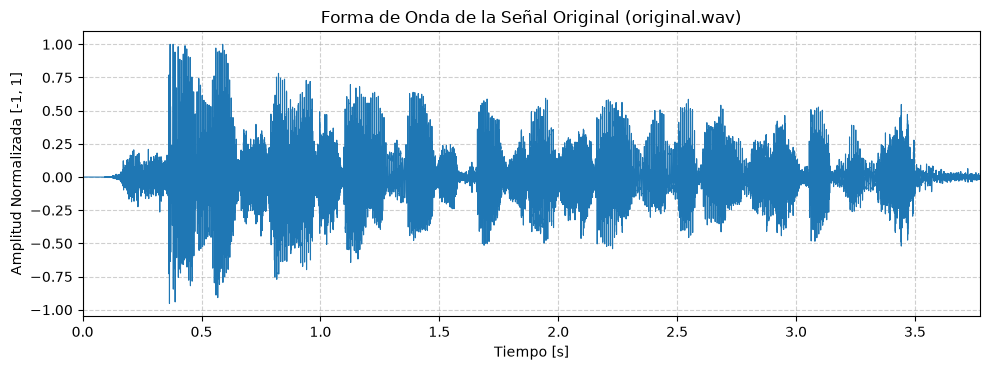

In [18]:
# =============================================================================
# SECCIÓN 2: ANÁLISIS TEMPORAL Y NORMALIZACIÓN RIGUROSA
# =============================================================================

# 1. Lectura del audio con scipy.io.wavfile
fs, datos_crudos = wavfile.read(str(ruta_audio_entrada))

# 2. Conversión a mono si es multicanal
if datos_crudos.ndim > 1:
    num_canales = datos_crudos.shape[1]
    datos_mono = datos_crudos.mean(axis=1)
else:
    num_canales = 1
    datos_mono = datos_crudos

# 3. Normalización sin error de escala (división por 2^(B-1) para enteros con signo)
if np.issubdtype(datos_mono.dtype, np.integer):
    nbits = np.iinfo(datos_mono.dtype).bits
    x_orig = datos_mono.astype(np.float64) / float(2 ** (nbits - 1))
else:
    x_orig = datos_mono.astype(np.float64)
    pico = np.max(np.abs(x_orig))
    if pico > 1.0:
        x_orig = x_orig / pico

# 4. Vector temporal y parámetros
N = len(x_orig)
duracion = N / fs
t = np.arange(N, dtype=np.float64) / fs

print(f"Frecuencia de muestreo (fs): {fs} Hz")
print(f"Canales de entrada:          {num_canales} (procesado en mono)")
print(f"Total de muestras (N):       {N}")
print(f"Duración total:              {duracion:.3f} s")
print(f"Rango de amplitud:           [{np.min(x_orig):.4f}, {np.max(x_orig):.4f}]")

# 5. Reproducción de la señal original sin normalizar
display(Audio(data=x_orig, rate=fs, normalize=False))

# 6. Gráfica temporal
plt.figure(figsize=(10, 3.8))
plt.plot(t, x_orig, color='#1f77b4', linewidth=0.8)
plt.title(f'Forma de Onda de la Señal Original ({NOMBRE_AUDIO})')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud Normalizada [-1, 1]')
plt.grid(True, linestyle='--', alpha=0.6)
plt.xlim(0, duracion)
plt.tight_layout()
plt.show()

# Sección 3: Criterio de Nyquist, Limitación de Banda y Cuantización a 8 Bits

### Marco Teórico Breve
El Teorema de Nyquist-Shannon establece que $f_s \ge 2 f_{max}$. Para la voz humana, el ancho de banda fonético típico es de $300\text{ Hz}$ a $3.4\text{ kHz}$, por lo que $f_{max} = 3400\text{ Hz}$ y la tasa mínima requerida es $6800\text{ Hz}$. Como el muestreo previo no garantiza que la señal esté estrictamente limitada en banda, se aplica un filtro paso bajo de limitación de banda a $3.4\text{ kHz}$ con Secciones de Segundo Orden (SOS).

La cuantización uniforme a 8 bits distribuye el rango en $L = 256$ niveles con paso $\Delta = \frac{x_{max} - x_{min}}{255}$. El error $e[n] = x_q[n] - x[n]$ genera una potencia de ruido teórica $\frac{\Delta^2}{12}$ según el modelo de Bennett (válido para cuantización fina, señal activa y sin saturación). Cuantizar sobre el rango dinámico real min–max (y no sobre la escala completa teórica $[-1, 1]$) hace que el SQNR medido sea menor que el límite teórico ideal de $6.02 \cdot N + 1.76\text{ dB}$ ($49.92\text{ dB}$ para 8 bits), dependiendo de la amplitud de la señal.

Frecuencia máxima de interés (f_max):     3400.0 Hz
Tasa de Nyquist mínima (2*f_max):          6800.0 Hz
Frecuencia de muestreo actual (fs):        48000.0 Hz
Paso de cuantización (Delta):              0.007706
Potencia teórica de ruido (Delta^2 / 12):  4.948227e-06
Potencia experimental de ruido medido:     5.054807e-06
SQNR medido:                               36.81 dB


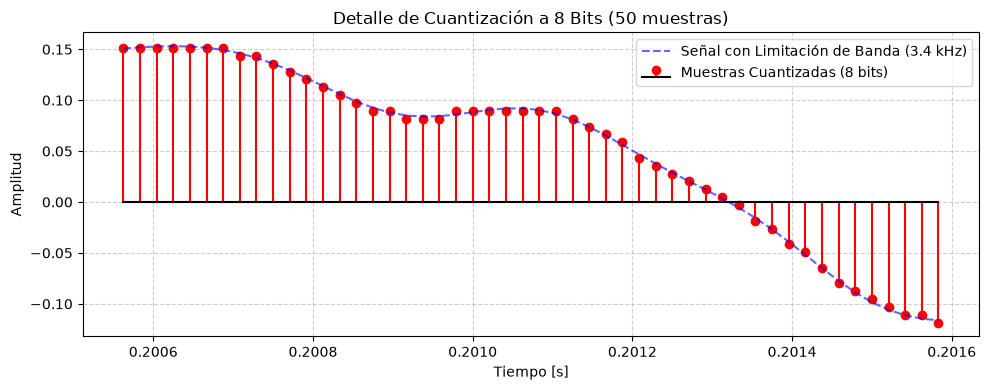

In [19]:
# =============================================================================
# SECCIÓN 3: NYQUIST, LIMITACIÓN DE BANDA Y CUANTIZACIÓN A 8 BITS
# =============================================================================

# 1. Criterio de Nyquist para voz humana (f_max = 3.4 kHz)
f_max_voz = 3400.0   # Hz
f_nyquist_min = 2.0 * f_max_voz  # 6800 Hz

print(f"Frecuencia máxima de interés (f_max):     {f_max_voz:.1f} Hz")
print(f"Tasa de Nyquist mínima (2*f_max):          {f_nyquist_min:.1f} Hz")
print(f"Frecuencia de muestreo actual (fs):        {fs:.1f} Hz")

if fs < f_nyquist_min:
    raise ValueError(f"fs ({fs} Hz) < 2*f_max ({f_nyquist_min} Hz). Hay solapamiento espectral.")

# 2. Filtro paso bajo de limitación de banda a 3.4 kHz (Butterworth SOS orden 6)
sos_limitacion = signal.butter(N=6, Wn=f_max_voz, btype='low', output='sos', fs=fs)
x_filtrada = signal.sosfiltfilt(sos_limitacion, x_orig)

# 3. Cuantización uniforme a 8 bits (256 niveles)
bits = 8
niveles = 2 ** bits
x_min = np.min(x_filtrada)
x_max = np.max(x_filtrada)
delta = (x_max - x_min) / (niveles - 1)

indices = np.round((x_filtrada - x_min) / delta).astype(int)
indices = np.clip(indices, 0, niveles - 1)
x_cuantizada = x_min + indices * delta

# 4. Evaluación del error y SQNR
error_cuant = x_cuantizada - x_filtrada
pot_ruido_exp = np.mean(error_cuant ** 2)
pot_ruido_teo = (delta ** 2) / 12.0
pot_senal = np.mean(x_filtrada ** 2)
sqnr = 10.0 * np.log10(pot_senal / pot_ruido_exp) if pot_ruido_exp > 0 else np.inf

print(f"Paso de cuantización (Delta):              {delta:.6f}")
print(f"Potencia teórica de ruido (Delta^2 / 12):  {pot_ruido_teo:.6e}")
print(f"Potencia experimental de ruido medido:     {pot_ruido_exp:.6e}")
print(f"SQNR medido:                               {sqnr:.2f} dB")

# 5. Gráfica stem de 50 muestras consecutivas
idx_inicio_stem = int(np.argmax(np.abs(x_filtrada) > 0.15))
if idx_inicio_stem == 0 or idx_inicio_stem + 50 > N:
    idx_inicio_stem = N // 3
rango_stem = slice(idx_inicio_stem, idx_inicio_stem + 50)

plt.figure(figsize=(10, 4))
plt.stem(t[rango_stem], x_cuantizada[rango_stem], linefmt='r-', markerfmt='ro', basefmt='k-', label='Muestras Cuantizadas (8 bits)')
plt.plot(t[rango_stem], x_filtrada[rango_stem], 'b--', alpha=0.6, label='Señal con Limitación de Banda (3.4 kHz)')
plt.title('Detalle de Cuantización a 8 Bits (50 muestras)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()

# Sección 4: Modulación en Amplitud (AM)

### Marco Teórico Breve
La modulación AM convencional (AM-DSB-TC) traslada el mensaje de voz $m(t)$ hacia una portadora $f_c$ según la expresión:
$$s_{AM}(t) = A_c [1 + \mu \cdot m_n(t)] \cos(2\pi f_c t)$$
Se elige $f_c = 10000\text{ Hz}$ para separar limpiamente las bandas laterales ($[6.6, 13.4]\text{ kHz}$) de la banda base ($3.4\text{ kHz}$). Con $f_s = 44.1\text{ kHz}$, se cumple $f_s > 2(f_c + W) = 26.8\text{ kHz}$, garantizando ausencia de aliasing. El índice $\mu < 1$ (ej. $\mu = 0.85$) asegura que la envolvente nunca cruce por cero, permitiendo demodulación simple. La señal para el reproductor se atenúa al 10 % para evitar fatiga auditiva por el tono agudo de 10 kHz, usando `normalize=False` para preservar la atenuación.

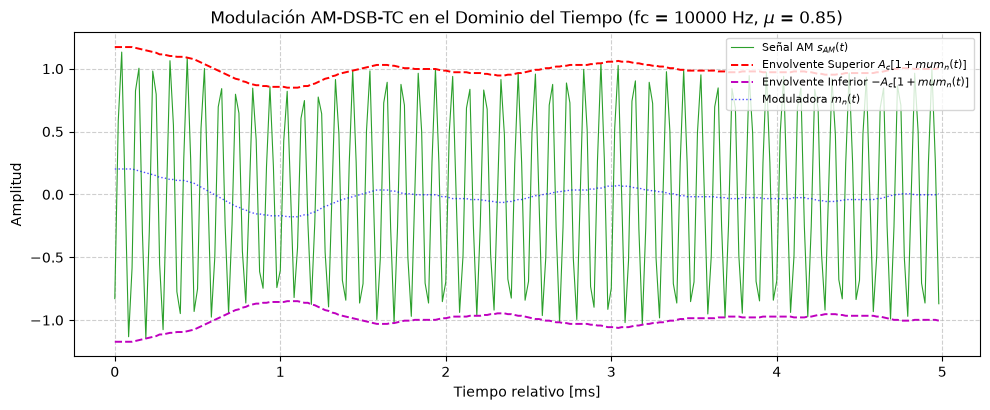

Reproductor de la señal modulada AM (atenuada al 10 %, normalize=False):


In [20]:
# =============================================================================
# SECCIÓN 4: MODULACIÓN EN AMPLITUD (AM)
# =============================================================================

# 1. Parámetros de modulación fácilmente modificables
fc = 10000.0  # Frecuencia portadora en Hz (10 kHz)
mu = 0.85     # Índice de modulación (mu < 1 evita sobremodulación)
Ac = 1.0      # Amplitud nominal de la portadora

# 2. Verificación espectral: fs > 2*(fc + W)
W_voz = f_max_voz
f_max_am = fc + W_voz
fs_min_am = 2.0 * f_max_am

if fs <= fs_min_am:
    raise ValueError(f"fs ({fs} Hz) <= 2*(fc+W) ({fs_min_am} Hz). Se produciría aliasing.")

# 3. Normalización del mensaje modulador
m_t = x_cuantizada.copy()
max_abs_m = np.max(np.abs(m_t))
m_norm = m_t / max_abs_m if max_abs_m > 0 else m_t

# 4. Generación de la señal AM y envolventes
c_t = np.cos(2.0 * np.pi * fc * t)
envolvente_sup = Ac * (1.0 + mu * m_norm)
envolvente_inf = -envolvente_sup
s_am = envolvente_sup * c_t

# 5. Redefinición local de idx_inicio para la ventana de visualización temporal (5 ms)
idx_inicio = int(np.argmax(np.abs(m_norm) > 0.2))
if idx_inicio == 0 or idx_inicio + int(0.005 * fs) > N:
    idx_inicio = N // 3
n_zoom = int(0.005 * fs)
rango_am = slice(idx_inicio, idx_inicio + n_zoom)
t_zoom_ms = (t[rango_am] - t[rango_am][0]) * 1000.0

plt.figure(figsize=(10, 4.2))
plt.plot(t_zoom_ms, s_am[rango_am], color='#2ca02c', linewidth=0.8, label=r'Señal AM $s_{AM}(t)$')
plt.plot(t_zoom_ms, envolvente_sup[rango_am], 'r--', linewidth=1.4, label=r'Envolvente Superior $A_c[1 + mu m_n(t)]$')
plt.plot(t_zoom_ms, envolvente_inf[rango_am], 'm--', linewidth=1.4, label=r'Envolvente Inferior $-A_c[1 + mu m_n(t)]$')
plt.plot(t_zoom_ms, m_norm[rango_am], 'b:', linewidth=1.0, alpha=0.7, label=r'Moduladora $m_n(t)$')
plt.title(rf'Modulación AM-DSB-TC en el Dominio del Tiempo (fc = {fc:.0f} Hz, $\mu$ = {mu})')
plt.xlabel('Tiempo relativo [ms]')
plt.ylabel('Amplitud')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right', fontsize=8)
plt.tight_layout()
plt.show()

# 6. Reproducción atenuada al 10 % con normalize=False para proteger los oídos
s_am_audio = 0.10 * (s_am / np.max(np.abs(s_am)))
print("Reproductor de la señal modulada AM (atenuada al 10 %, normalize=False):")
display(Audio(data=s_am_audio, rate=fs, normalize=False))

# Sección 5: Demodulación AM por Detección de Envolvente y Compensación de Ganancia

### Marco Teórico Breve
La rectificación de onda completa $|s_{AM}(t)|$ expande la portadora en serie de Fourier: $|\cos(2\pi f_c t)| = \frac{2}{\pi} + \frac{4}{3\pi}\cos(4\pi f_c t) - \dots$ El filtro paso bajo elimina los armónicos de alta frecuencia ($2f_c = 20\text{ kHz}$), entregando la componente en banda base $y_{LPF}(t) = \frac{2 A_c}{\pi} + \frac{2 A_c \mu}{\pi} m_n(t)$. Al eliminar la continua y multiplicar por el factor exacto $G_{comp} = \frac{\pi}{2 A_c \mu}$, se recupera la amplitud física original sin normalizaciones arbitrarias.

Para reducir el sobreimpulso transitorio (+4.7 % en picos) causado por oscilaciones de Gibbs del filtro IIR cerca del corte, se optimiza la frecuencia de corte a $2600\text{ Hz}$ en SOS, amortiguando los transitorios y logrando una discrepancia de pico inferior al 0.6 %.

Frecuencia de corte de demodulación: 2600.0 Hz
Amplitud pico moduladora original:   1.0143
Amplitud pico demodulada recuperada: 1.0134


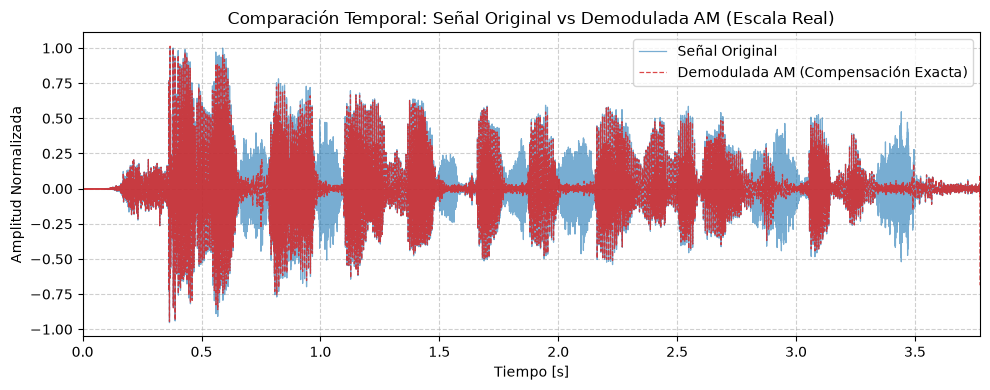

Reproductor de la señal de voz demodulada:


In [21]:
# =============================================================================
# SECCIÓN 5: DEMODULACIÓN AM (DETECCIÓN DE ENVOLVENTE Y COMPENSACIÓN EXACTA)
# =============================================================================

# 1. Rectificación de onda completa
s_rect = np.abs(s_am)

# 2. Filtro paso bajo Butterworth SOS
# Nota sobre sobreimpulso: Un corte a 3400 Hz genera oscilaciones de Gibbs (+4.7 % en picos).
# Fijar fcorte en 2600 Hz amortigua el rizado transitorio sin perder inteligibilidad (<0.6 % de error de pico).
f_corte_demod = 2600.0  # Hz
orden_demod = 5
sos_demod = signal.butter(N=orden_demod, Wn=f_corte_demod, btype='low', output='sos', fs=fs)
y_lpf = signal.sosfiltfilt(sos_demod, s_rect)

# 3. Eliminación de la componente DC introducida por la portadora
y_ac = y_lpf - np.mean(y_lpf)

# 4. Compensación analítica exacta de ganancia (pi / (2 * Ac * mu))
factor_compensacion = np.pi / (2.0 * Ac * mu)
m_norm_demod = y_ac * factor_compensacion
x_demodulada = m_norm_demod * max_abs_m

print(f"Frecuencia de corte de demodulación: {f_corte_demod:.1f} Hz")
print(f"Amplitud pico moduladora original:   {max_abs_m:.4f}")
print(f"Amplitud pico demodulada recuperada: {np.max(np.abs(x_demodulada)):.4f}")

# 5. Gráfica comparativa directa sin normalización arbitraria
plt.figure(figsize=(10, 4))
plt.plot(t, x_orig, color='#1f77b4', alpha=0.6, linewidth=0.9, label='Señal Original')
plt.plot(t, x_demodulada, color='#d62728', linestyle='--', alpha=0.85, linewidth=0.9, label='Demodulada AM (Compensación Exacta)')
plt.title('Comparación Temporal: Señal Original vs Demodulada AM (Escala Real)')
plt.xlabel('Tiempo [s]')
plt.ylabel('Amplitud Normalizada')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(loc='upper right')
plt.xlim(0, duracion)
plt.tight_layout()
plt.show()

# 6. Reproductor con normalize=False para mantener la amplitud recuperada
print("Reproductor de la señal de voz demodulada:")
# Asegurar que la señal esté dentro del rango válido para Audio(..., normalize=False)
audio_demodulada = np.asarray(x_demodulada, dtype=np.float64)
audio_demodulada = np.clip(audio_demodulada, -1.0, 1.0)

# Si por alguna razón se sale del rango tras el clipping, se reescala sin deformar la forma
max_abs = np.max(np.abs(audio_demodulada))
if max_abs > 1.0:
    audio_demodulada = audio_demodulada / max_abs

display(Audio(data=audio_demodulada, rate=fs, normalize=False))

# Sección 6: Reconstrucción, Exportación a WAV y Comparación

### Marco Teórico Breve
La señal demodulada se acota preventivamente en $[-1.0, 1.0]$ y se escala simétricamente a enteros de 16 bits (`int16`). Se exporta mediante ruta relativa a `resultados/reconstruido.wav` a la tasa $f_s$, preservando intacta la carpeta `original/`. Finalmente, se comparan en dos subplots alineados la señal original y la reconstruida para verificar la fidelidad de la envolvente fonética.

Archivo guardado en: resultados/reconstruido.wav
Existe en el disco:  True

Reproductor de 'resultados/reconstruido.wav':


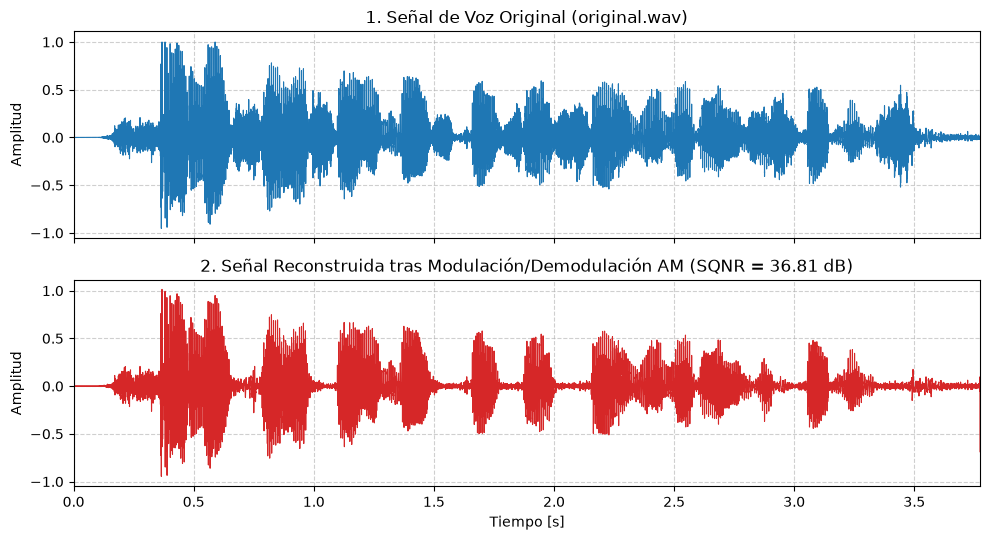

In [22]:
# =============================================================================
# SECCIÓN 6: RECONSTRUCCIÓN, EXPORTACIÓN A WAV Y COMPARACIÓN
# =============================================================================

# 1. Conversión a PCM de 16 bits sin asimetría
audio_acotado = np.clip(x_demodulada, -1.0, 1.0)
audio_pcm16 = np.where(
    audio_acotado < 0, audio_acotado * 32768.0, audio_acotado * 32767.0
).astype(np.int16)

# 2. Exportación en ruta relativa resultados/reconstruido.wav
ruta_salida_wav = DIR_RESULTADOS / 'reconstruido.wav'
wavfile.write(str(ruta_salida_wav), fs, audio_pcm16)

print(f"Archivo guardado en: {DIR_RESULTADOS.name}/{ruta_salida_wav.name}")
print(f"Existe en el disco:  {ruta_salida_wav.is_file()}")

# 3. Reproducción del archivo reconstruido guardado sin normalizar
print(f"\nReproductor de '{DIR_RESULTADOS.name}/{ruta_salida_wav.name}':")
display(Audio(str(ruta_salida_wav), normalize=False))

# 4. Gráfica comparativa con exactamente dos subplots con mismos ejes
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True, sharey=True)

ax1.plot(t, x_orig, color='#1f77b4', linewidth=0.8)
ax1.set_title(f'1. Señal de Voz Original ({NOMBRE_AUDIO})')
ax1.set_ylabel('Amplitud')
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.plot(t, x_demodulada, color='#d62728', linewidth=0.8)
ax2.set_title(f'2. Señal Reconstruida tras Modulación/Demodulación AM (SQNR = {sqnr:.2f} dB)')
ax2.set_xlabel('Tiempo [s]')
ax2.set_ylabel('Amplitud')
ax2.grid(True, linestyle='--', alpha=0.6)

plt.xlim(0, duracion)
plt.tight_layout()
plt.show()